In [ ]:

import numpy as np
import matplotlib.pyplot as plt

from centerline.utils import array_to_o3d
from pc_skeletor import LBC
from stl import mesh

In [5]:
meshdata = mesh.Mesh.from_file("./tests/meshes/Archamps.stl")

In [9]:
pcd = meshdata.centroids
    
# local shift
local_shift = np.mean(pcd, axis = 0)

# convert to open3d object-
shifted_pcd = array_to_o3d(pcd - local_shift)

In [32]:
shifted_pcd

PointCloud with 571513 points.

In [33]:
skeleton_clouds = []

skeleton_clouds.append(shifted_pcd)

for max_it_step in range(1,6):
    # set up the Laplacian-based contraction algorithm 
    lbc = LBC(point_cloud=shifted_pcd, 
              down_sample=0.2,
              init_attraction = 2, 
              init_contraction = 0.5, 
              max_iteration_steps=max_it_step)
    lbc.extract_skeleton()
    skeleton_clouds.append(lbc.contracted_point_cloud)

2025-03-07 09:38:09,337 - PCD #points: 15055
Current volume ratio 1.0. Contraction weights 86.20522223499911. Attraction weights 2.0. Progress LBC: 100%|█| 1/1 [00:2025-03-07 09:38:17,303 - Contraction is Done.
Current volume ratio 1.0. Contraction weights 86.20522223499911. Attraction weights 2.0. Progress LBC: 100%|█| 1/1 [00:

Contraction is Done.



2025-03-07 09:38:17,540 - PCD #points: 15055
Current volume ratio 1.0. Contraction weights 431.0261111749953. Attraction weights 2.0. Progress LBC: 100%|█| 2/2 [00:2025-03-07 09:38:30,975 - Contraction is Done.
Current volume ratio 1.0. Contraction weights 431.0261111749953. Attraction weights 2.0. Progress LBC: 100%|█| 2/2 [00:

Contraction is Done.



2025-03-07 09:38:31,194 - PCD #points: 15055
Current volume ratio 1.0. Contraction weights 2048.0. Attraction weights 3.227695091967817. Progress LBC: 100%|█| 3/3 [2025-03-07 09:38:47,035 - Contraction is Done.
Current volume ratio 1.0. Contraction weights 2048.0. Attraction weights 3.227695091967817. Progress LBC: 100%|█| 3/3 [

Contraction is Done.



2025-03-07 09:38:47,252 - PCD #points: 15055
Current volume ratio 0.560371171209983. Contraction weights 2048.0. Attraction weights 32.11570537852584. Progress LBC:2025-03-07 09:39:06,004 - Contraction is Done.
Current volume ratio 0.560371171209983. Contraction weights 2048.0. Attraction weights 32.11570537852584. Progress LBC:

Contraction is Done.



2025-03-07 09:39:06,226 - PCD #points: 15055
Current volume ratio 0.560371171209983. Contraction weights 2048.0. Attraction weights 32.11570537852584. Progress LBC:2025-03-07 09:39:25,278 - Contraction is Done.
Current volume ratio 0.560371171209983. Contraction weights 2048.0. Attraction weights 32.11570537852584. Progress LBC:

Contraction is Done.


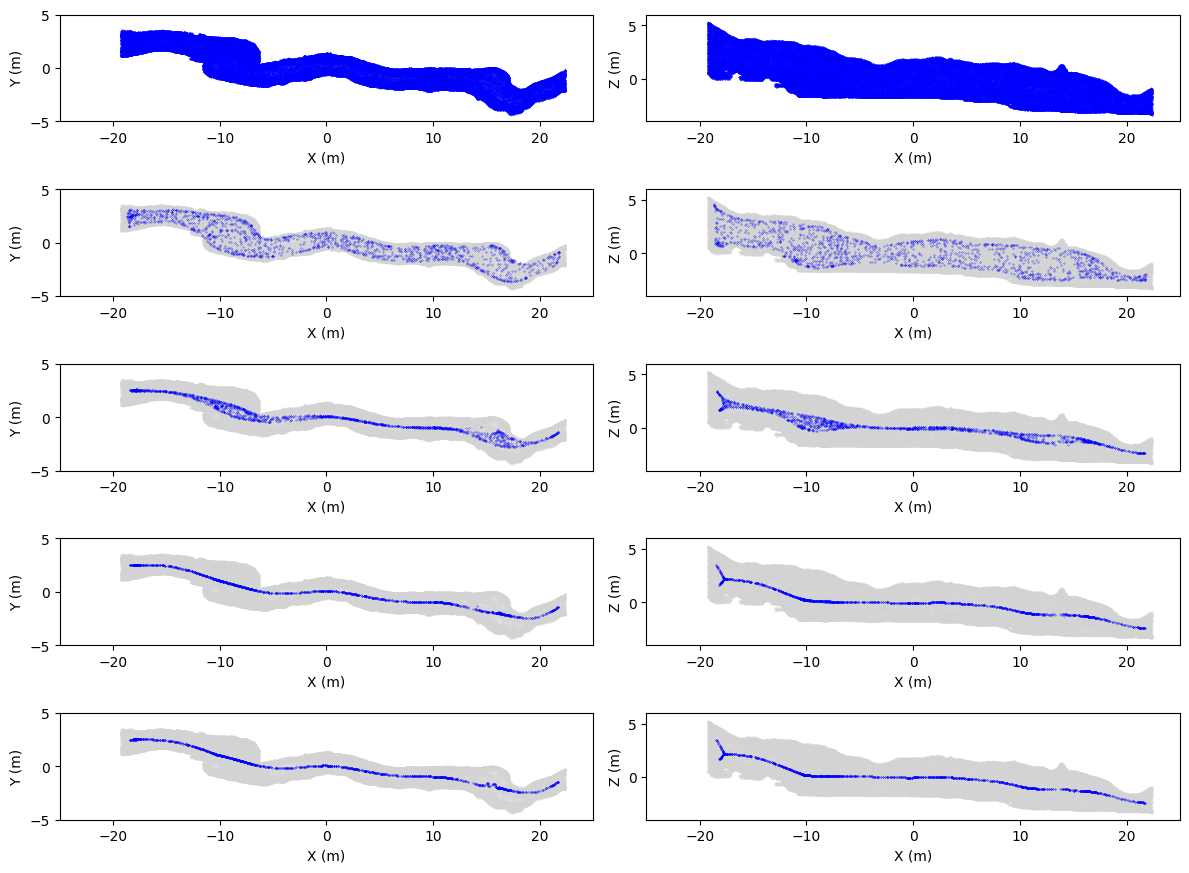

In [52]:
fig, axes = plt.subplots(5,2, figsize =(12, 9))

for i in range(0,5):
    axes[i, 0].scatter(*np.asarray(skeleton_clouds[i].points)[::10, [0,1]].T, color = "blue", s=0.05, zorder = 100)
    axes[i, 0].scatter(*np.asarray(skeleton_clouds[0].points)[::10, [0,1]].T, color = "lightgrey", s=0.05, zorder = -100, alpha = 0.5)

    axes[i, 0].set_aspect("equal")
    axes[i, 0].set_xlim(-25,25)
    axes[i, 0].set_ylim(-5,5)
    axes[i, 0].set_xlabel("X (m)")
    axes[i, 0].set_ylabel("Y (m)")

    axes[i, 1].scatter(*np.asarray(skeleton_clouds[i].points)[::10, [0,2]].T, color = "blue", s=0.05, zorder = 100)
    axes[i, 1].scatter(*np.asarray(skeleton_clouds[0].points)[::10, [0,2]].T, color = "lightgrey", s=0.05, zorder = -100, alpha = 0.5)

    axes[i, 1].set_aspect("equal")
    axes[i, 1].set_xlim(-25,25)
    axes[i, 1].set_ylim(-4,6)
    axes[i, 1].set_xlabel("X (m)")
    axes[i, 1].set_ylabel("Z (m)")




plt.tight_layout()

plt.savefig("tests/outputs/iterative_contraction.png")

In [23]:
lbc.contracted_point_cloud

PointCloud with 15055 points.